<a href="https://colab.research.google.com/github/conganh1982006-dotcom/SE-ROCKET-SIMULATION/blob/main/numerical_no_drag_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [129]:
import numpy as np
import matplotlib.pyplot as plt

In [130]:
h = 0.2 #step
t = np.arange(0, 2 + h, h)
Y = np.zeros(len(t)) #create array (similar to Y[]={0} in C)
m = np.zeros(len(t))
v_improve = np.zeros(len(t)) #huen
v_rk = np.zeros(len(t)) #rk4

m[0] = 1
Y[0] = 0 #intial value
ve=500
me=0.2
g=9.81
print(t)

[0.  0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2. ]


In [131]:
v_exact = ve * np.log(m[0] / (m[0] - me * t)) - g * t #exact solution

for i in range(len(t) - 1):
    m[i+1] = m[i] - me * h
    m_mid  = m[i] - me * h / 2
    Y[i + 1] = Y[i] + h * ((ve * me) / m[i] - g)  #euler method
    y1 = ((ve * me) / m[i] - g)
    y2 = ((ve * me) / m[i+1] - g)
    v_improve[i+1] = v_improve[i] + h/2 * (y1 + y2) #improved euler method
    k1 = y1
    k2 = (ve * me) / m_mid  - g
    k3 = (ve * me) / m_mid  - g
    k4 = y2
    v_rk[i+1] = v_rk[i] + h/6 * (k1 + 2*k2 + 2*k3 + k4) #rk4 method

print(v_exact[-1])
print(Y[-1])
print(v_improve[-1])
print(v_rk[-1])

235.79281188299535
229.24459226225687
235.9112589289236
235.79282974082605


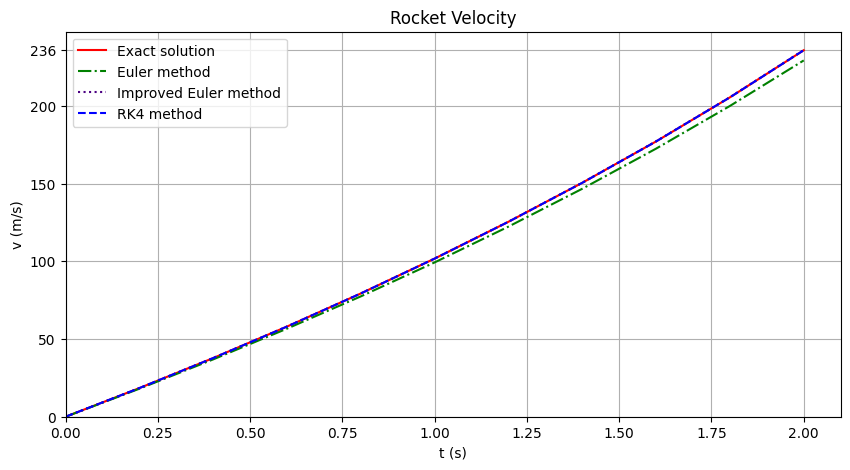

In [132]:
plt.subplots(figsize=(10,5))
plt.plot(t, v_exact, label='Exact solution', color ='red')
plt.plot(t, Y, label='Euler method', linestyle='-.', color='green')
plt.plot(t, v_improve, label ='Improved Euler method', linestyle='dotted', color='indigo')
plt.plot(t, v_rk, label ='RK4 method', linestyle='--', color='blue')

#max value
max_y = max(np.max(Y), np.max(v_exact), np.max(v_improve))
ticks = [t for t in plt.yticks()[0] if t < max_y]
ticks.append(max_y)
plt.yticks(ticks)

plt.ylim(bottom=0)
plt.xlim(left=0)

plt.title('Rocket Velocity')
plt.xlabel('t (s)')
plt.ylabel('v (m/s)')
plt.grid(True)
plt.legend()
plt.show()

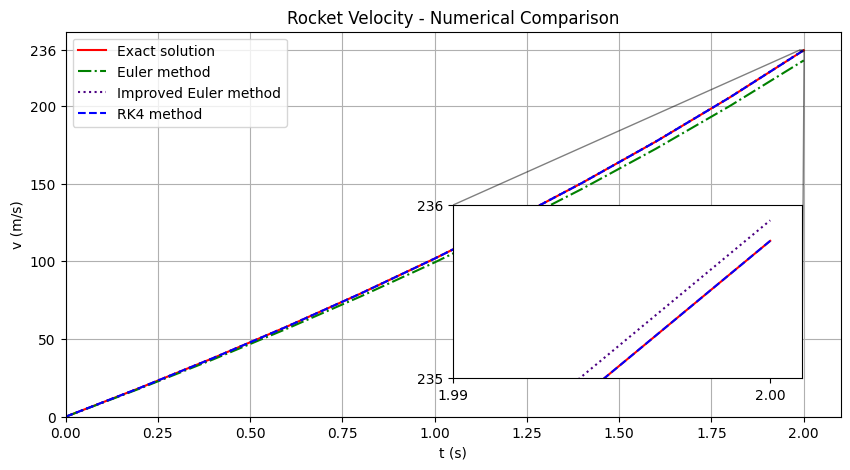

In [133]:

#zoom in
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(t, v_exact, label="Exact solution", color="red")
ax.plot(t, Y, label="Euler method", linestyle="-.", color="green")
ax.plot(t, v_improve, label="Improved Euler method", linestyle=":", color="indigo")
ax.plot(t, v_rk, label ='RK4 method', linestyle='--', color='blue')
x1, x2, y1, y2 = 1.995, 2.001, 235, 236
axins = ax.inset_axes([0.5, 0.1, 0.45, 0.45], xlim=(x1, x2), ylim=(y1, y2))
max_y = max(np.max(Y), np.max(v_exact), np.max(v_improve))
ticks = [t for t in plt.yticks()[0] if t < max_y]
ticks.append(max_y)
plt.yticks(ticks)

plt.ylim(bottom=0)
plt.xlim(left=0)

axins.plot(t, v_exact, label='Exact solution', color ='red')
axins.plot(t, Y, label='Euler method', linestyle='dashdot', color='green')
axins.plot(t, v_improve, label ='Improved Euler method', linestyle='dotted', color='indigo')
axins.plot(t, v_rk, label ='RK4 method', linestyle='--', color='blue')
axins.set_xticks([1.99, 2.0])
axins.set_yticks([235, 236])

ax.indicate_inset_zoom(axins, edgecolor="black")


plt.title('Rocket Velocity - Numerical Comparison')
plt.xlabel('t (s)')
plt.ylabel('v (m/s)')
plt.grid(True)
plt.legend()
plt.show()